# Transcript normalization
Exploratory measurements; inference only. No training or API calls.

- Development controls are authored regression examples, not independent accuracy evidence.
- Audio reading prompts can differ from what a learner actually said.
- Small exploratory sample, not a calibration set or evidence of conversational ASR reliability.
- WER/CER ignore capitalization/punctuation; guard checks are invariants, not semantic human judgments.
- No training, threshold fitting, external API, LLM judge, or paid TTS.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
OUT = ROOT / 'data/generated/transcript-normalization-v1'
results = json.loads((OUT / 'results.json').read_text(encoding='utf-8'))

In [2]:
display(pd.DataFrame(results['summary']).T)

,sentences,reference_words,statuses,changed,guard_violations,wer_before,cer_before,wer_qwen_unguarded,cer_qwen_unguarded,wer_after,cer_after,improved,worsened,same_word_errors,correct_transcripts_damaged,mean_normalization_sec
controls,16,80,{'accepted': 16},16,0,0.0625,0.008152,0.0,0.0,0.0,0.0,3,0,13,0,4.752937
audio,12,114,"{'rejected': 4, 'accepted': 8}",8,0,0.166667,0.071066,0.131579,0.060914,0.166667,0.071066,0,0,12,0,5.042833


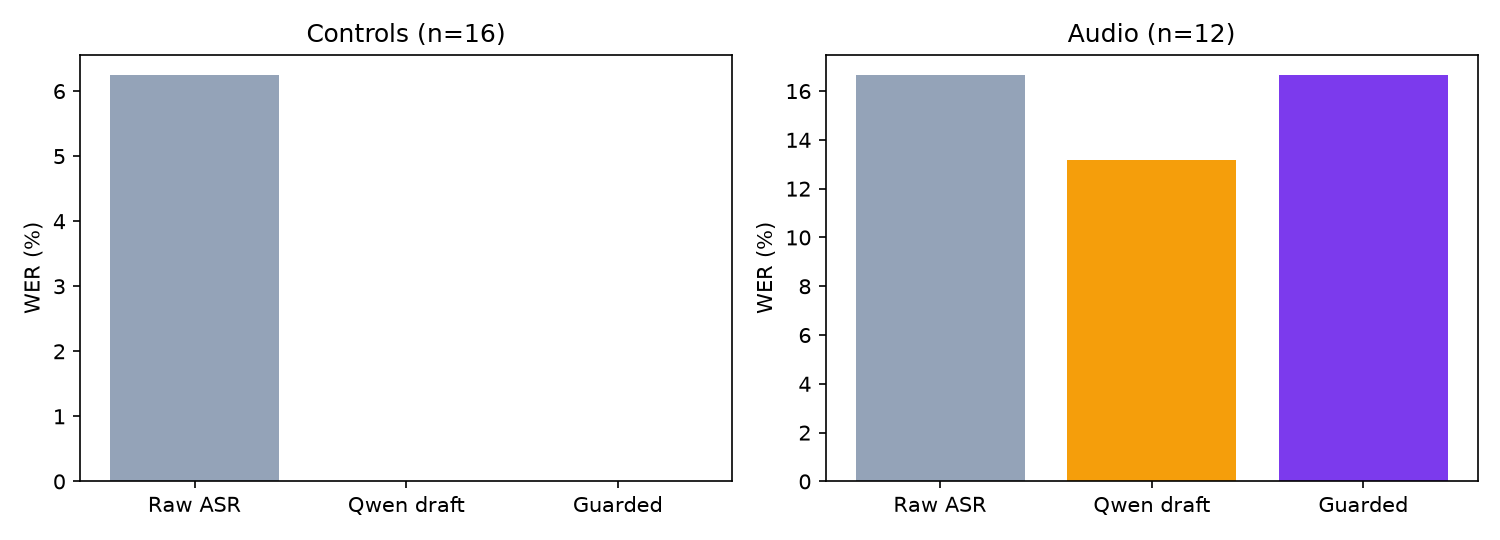

In [3]:
display(Image(filename=str(OUT / 'wer.png')))

In [4]:
rows = pd.DataFrame(results['records'])
display(rows[['group', 'id', 'transcript', 'proposal', 'normalized', 'reference']])

,group,id,transcript,proposal,normalized,reference
0,controls,format,i work as an engineer,I work as an engineer.,I work as an engineer.,I work as an engineer.
1,controls,compound,i am a soft ware engineer,I am a software engineer.,I am a software engineer.,I am a software engineer.
2,controls,compound-negation,i do not repair hard ware,I do not repair hardware.,I do not repair hardware.,I do not repair hardware.
3,controls,apostrophe,i dont like coffee,I don't like coffee.,I don't like coffee.,I don't like coffee.
4,controls,keep-grammar,i usually wakes up at seven am,I usually wakes up at seven am.,I usually wakes up at seven am.,I usually wakes up at seven am.
5,controls,keep-past-errors,Yesterday I wake up then I no brush teeth,Yesterday I wake up. Then I no brush teeth.,Yesterday I wake up. Then I no brush teeth.,Yesterday I wake up. Then I no brush teeth.
6,controls,keep-repetition,I I want one coffee,I I want one coffee.,I I want one coffee.,I I want one coffee.
7,controls,keep-quantity,I want two coffees not three,"I want two coffees, not three.","I want two coffees, not three.","I want two coffees, not three."
8,controls,keep-uncertainty,maybe I might go tomorrow,Maybe I might go tomorrow.,Maybe I might go tomorrow.,Maybe I might go tomorrow.
9,controls,keep-name,My name is Curly,My name is Curly.,My name is Curly.,My name is Curly.


In [5]:
display(results['protocol'])

{'version': 'lexical_preserving_v1',
 'controls_sha256': '4681adc4ad93bee5a8e99207435af590d166ff99e80af08feefacc2ce9d7e83c',
 'normalizer_sha256': '052cbdf0abc0753412f22ad7abab63aef162159412f81c476af120dd9eca8103',
 'source_manifest': 'data\\processed\\feedback-projector-en-v1\\test.jsonl',
 'source_manifest_sha256': 'd7102165632d7d46019c53a20f060d62835ddf0c1e5bdf028aa078800b65d200',
 'audio_ids': ['NJS/arctic_a0233',
  'TLV/arctic_a0088',
  'TNI/arctic_a0007',
  'TXHC/arctic_a0122',
  'YKWK/arctic_a0106',
  'ZHAA/arctic_a0079',
  'NJS/arctic_a0185',
  'TLV/arctic_b0288',
  'TNI/arctic_a0131',
  'TXHC/arctic_a0108',
  'YKWK/arctic_b0518',
  'ZHAA/arctic_a0101'],
 'audio_limit': 12,
 'selection': 'speaker round robin, ordered by SHA256(utterance_id), duration <=20s; fixed before inference',
 'normalization_policy': 'No free lexical substitution; only orthography, closed apostrophe/compound rules',
 'models': {'Qwen3-0.6B': {'weights_sha256': 'f47f71177f32bcd101b7573ec9171e6a57f4f4d31148